# Cell-dependent latent shifts for scDisInFact

## Objective

In this notebook, we compare our cell-dependent shift with the original scDisInFact mean shift for predicting drug responses.

We follow the GBM prediction setup in the paper: we leave the treated sample `PW034-705` out of training and predict it from untreated cells in patient `PW034` or patient `PW030`. These are patient IDs; `PW034-705` is a sample from patient `PW034`. The first case changes treatment within the same patient, while the second also changes the patient batch.

We train scDisInFact first, freeze it, and then train our shift network. Both methods use the same denoised test reference, with seed 0.

The paper’s GBM script does not set aside a separate validation set. We add one to select our network checkpoint, so we also retrain the original model on our training split to keep the comparison fair.

In [3]:
from pathlib import Path
import os, sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'cellshift' / 'run.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Repository root not found: expected cellshift/run.py in a parent directory.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from cellshift.data import load_gbm, normalized, split
from cellshift.run import subset, scenarios, metrics, dump
from cellshift.model import Backbone, bandwidth_from_training, train_adapter
from cellshift.upstream import create_scdisinfact_dataset, scdisinfact, REVISION
print('CUDA available:', torch.cuda.is_available())


CUDA available: True


## Data acquisition

In this part, we download the processed GBM data shared by the paper’s authors on Zenodo. We check the file before extracting it into data. If the download is already complete and valid, we reuse it.


In [4]:
import subprocess

def run_visible(arguments):
    process = subprocess.Popen([sys.executable, '-u', '-m', *arguments], cwd=ROOT,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait() != 0:
            raise RuntimeError('Subprocess failed; inspect the preceding output.')
    except BaseException:
        process.terminate()
        process.wait()
        raise

run_visible(['cellshift.download', 'gbm'])


Ready: gbm


## Dataset composition

In this part, we look at the data before splitting it. Each row is a cell, and each column is a gene. The values are RNA counts. The metadata tell us each cell’s patient, sample, treatment, and cell type. The tables below show how many cells we have in each group.


Cells: 74,777; genes: 19,949


,batch,sample_id,treatment,cell_type
Cell_0,PW029,PW029-701,vehicle (DMSO),tumor
Cell_1,PW029,PW029-701,vehicle (DMSO),Oligodendrocytes
Cell_2,PW029,PW029-701,vehicle (DMSO),Oligodendrocytes
Cell_3,PW029,PW029-701,vehicle (DMSO),tumor
Cell_4,PW029,PW029-701,vehicle (DMSO),tumor
Cell_5,PW029,PW029-701,vehicle (DMSO),tumor
Cell_6,PW029,PW029-701,vehicle (DMSO),tumor
Cell_7,PW029,PW029-701,vehicle (DMSO),Myeloid
Cell_8,PW029,PW029-701,vehicle (DMSO),tumor
Cell_9,PW029,PW029-701,vehicle (DMSO),tumor


treatment,0.2 uM panobinostat,vehicle (DMSO)
cell_type,,
Myeloid,2123,9523
Oligodendrocytes,2168,8348
Other,140,1095
tumor,10150,41230


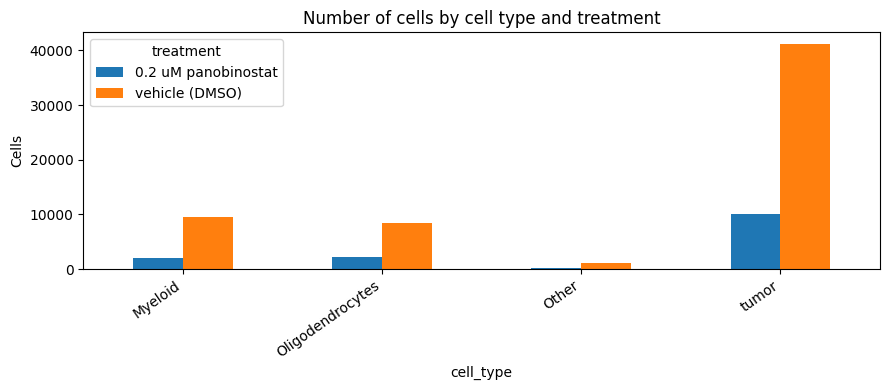

In [3]:
data = load_gbm(ROOT / 'data')
print(f'Cells: {data.counts.shape[0]:,}; genes: {data.counts.shape[1]:,}')
display(data.meta[['batch', 'sample_id', 'treatment', 'cell_type']].head(10))
populations = pd.crosstab(data.meta.cell_type, data.meta.treatment)
display(populations)
populations.plot.bar(figsize=(9, 4), title='Number of cells by cell type and treatment')
plt.ylabel('Cells'); plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()


## Training, validation, and test split

In this part, we keep sample `PW034-705` for testing. From the remaining cells, we set aside about 20% of each patient, cell-type, and treatment group for validation. We use validation to select the best checkpoint for our shift network.

Only training cells are used to train scDisInFact, fit the input scaler, and calculate the latent means. We save the split and use a fixed seed so we can repeat it.

Unlike our setup, the paper’s GBM script fits the scaler before separating the test sample and does not create a separate validation set.


In [4]:
SEED = 0
manifest, _ = split(data, 'gbm', SEED, min_cells=50)
display(pd.crosstab(manifest.role, manifest.treatment))
display(manifest.groupby(['role', 'batch', 'cell_type']).size().rename('cells').to_frame())
training = subset(data, manifest.role.eq('train'))
validation = subset(data, manifest.role.eq('val'))
assert not set(training.meta.index) & set(manifest.index[manifest.role.eq('test')])
print('Verified: training and test cell identifiers are disjoint.')


treatment,0.2 uM panobinostat,vehicle (DMSO)
role,,
test,2431,0
train,9725,48166
val,2425,12030


cells
role  batch cell_type              
test  PW034 Myeloid             265
            Oligodendrocytes    339
            Other                25
            tumor              1802
train PW029 Myeloid             114
            Oligodendrocytes    152
            Other                56
            tumor               876
      PW030 Myeloid            4037
            Oligodendrocytes   2665
            Other                89
            tumor             12044
      PW032 Myeloid            1949
            Oligodendrocytes    504
            Other               360
            tumor              3573
      PW034 Myeloid             454
            Oligodendrocytes    640
            Other                42
            tumor             10375
      PW036 Myeloid            1951
            Oligodendrocytes   1849
            Other               239
            tumor              7896
      PW040 Myeloid             603
            Oligodendrocytes   2334
            Other               187
            tumor              4902
val   PW029 Myeloid              28
            Oligodendrocytes     38
            Other                13
            tumor               219
      PW030 Myeloid            1008
            Oligodendrocytes    666
            Other                21
            tumor              3009
      PW032 Myeloid             487
            Oligodendrocytes    125
            Other                88
            tumor               893
      PW034 Myeloid             113
            Oligodendrocytes    160
            Other                10
            tumor              2593
      PW036 Myeloid             487
            Oligodendrocytes    461
            Other                59
            tumor              1973
      PW040 Myeloid             150
            Oligodendrocytes    583
            Other                46
            tumor              1225

Verified: training and test cell identifiers are disjoint.


## Experiment configuration

In this part, we set the training parameters. For scDisInFact, we use the paper’s GBM settings: latent dimensions `[8, 2]`, negative-binomial reconstruction, batch size 64, learning rate `5e-4`, and 100 epochs.

For our shift network, we use up to 100 epochs and 50 updates per epoch. We select the checkpoint with the lowest validation MMD and stop if it does not improve for 10 epochs.

Training uses the GPU when available. Set `ALLOW_CPU=True` to allow CPU training.

With `RESUME_DIRECTORY=None`, we start a new run. To continue a saved run, set it to that run’s output directory. The code checks the settings and split, then loads available checkpoints and results.

In [5]:
from datetime import datetime
import random
ALLOW_CPU = False
BASE_EPOCHS = 100
ADAPTER_EPOCHS = 100
STEPS = 50
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RESUME_DIRECTORY = None
OUT = (Path(RESUME_DIRECTORY).expanduser().resolve() if RESUME_DIRECTORY else
       ROOT / 'runs_notebook' / datetime.now().strftime('%Y%m%d_%H%M%S_%f') / 'gbm' / f'seed_{SEED}')
if RESUME_DIRECTORY and not (OUT / 'config.json').exists():
    raise FileNotFoundError(f'Experiment configuration not found: {OUT}')
OUT.mkdir(parents=True, exist_ok=True)
config = {'seed': SEED, 'revision': REVISION, 'base_epochs': BASE_EPOCHS,
          'adapter_epochs': ADAPTER_EPOCHS, 'steps': STEPS, 'device': str(DEVICE)}
if RESUME_DIRECTORY:
    import json
    saved_config = json.loads((OUT / 'config.json').read_text())
    for key in ['seed', 'revision', 'base_epochs', 'adapter_epochs', 'steps']:
        if saved_config[key] != config[key]:
            raise ValueError(f'Incompatible saved configuration: {key}')
    saved_split = pd.read_csv(OUT / 'split.csv', index_col=0)
    if not saved_split.index.equals(manifest.index) or not saved_split['role'].equals(manifest['role']):
        raise ValueError('Saved split does not match the current partition.')
else:
    manifest.to_csv(OUT / 'split.csv')
    dump(OUT / 'config.json', config)
print('Training device:', DEVICE)


Training device: cuda


## Backbone training

Here we train the original scDisInFact model using only the training cells. We then save their latent representations and calculate the mean representation for each treatment condition. The original method uses the difference between these means as its shift.

The training loop starts at epoch 0, so we pass `BASE_EPOCHS - 1` to run exactly 100 epochs. The loss shown below is measured on subsets of the training data, not on our separate validation or test cells.


Sanity check...
Finished.
Create scDisInFact datasets...
Finished.
Epoch 0, Validating Loss: 3.1891
	 loss reconstruction: 2.49795
	 loss kl comm: 0.14662
	 loss kl diff: 1.61417
	 loss mmd common: 5.63034
	 loss mmd diff: 67.35472
	 loss classification: 0.60568
	 loss group lasso diff: 0.06204
GPU memory usage: 1058.382324MB
Epoch 10, Validating Loss: 0.6393
	 loss reconstruction: 0.42785
	 loss kl comm: 20.01924
	 loss kl diff: 6.02485
	 loss mmd common: 13.14342
	 loss mmd diff: 5.65649
	 loss classification: 0.07832
	 loss group lasso diff: 0.07077
GPU memory usage: 1058.382324MB
Epoch 20, Validating Loss: 0.5732
	 loss reconstruction: 0.40269
	 loss kl comm: 19.06589
	 loss kl diff: 5.57038
	 loss mmd common: 6.77745
	 loss mmd diff: 4.44986
	 loss classification: 0.04373
	 loss group lasso diff: 0.06977
GPU memory usage: 1058.382324MB
Epoch 30, Validating Loss: 0.5474
	 loss reconstruction: 0.39330
	 loss kl comm: 17.88495
	 loss kl diff: 5.08120
	 loss mmd common: 5.78928
	 loss

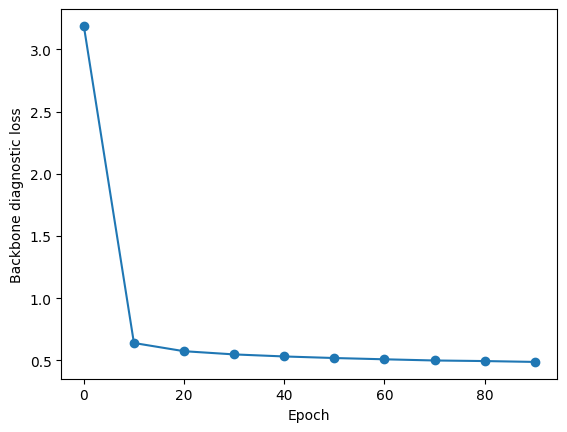

Backbone ready.


In [6]:
if DEVICE.type == 'cpu' and not ALLOW_CPU:
    raise RuntimeError('CUDA is unavailable. Set ALLOW_CPU=True to explicitly permit CPU training.')
torch.set_num_threads(4)
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
dictionary = create_scdisinfact_dataset(training.counts, training.meta.copy(),
    condition_key=data.conditions, batch_key='batch', batch_cond_key='sample_id')
dims = [8, 2]
base = scdisinfact(dictionary, Ks=dims, batch_size=64, lr=5e-4, seed=SEED, device=DEVICE)
if (OUT / 'backbone.pt').exists():
    checkpoint = torch.load(OUT / 'backbone.pt', map_location=DEVICE, weights_only=False)
    base.load_state_dict(checkpoint['state_dict'])
    base.data_dict['scaler'] = checkpoint['scaler']
    import json
    losses = json.loads((OUT / 'base_losses.json').read_text()) if (OUT / 'base_losses.json').exists() else None
    print('Backbone checkpoint loaded.')
else:
    losses = base.train_model(nepochs=BASE_EPOCHS - 1, recon_loss='NB')
    torch.save({'state_dict': base.state_dict(), 'scaler': dictionary['scaler'],
                'matching_dict': dictionary['matching_dict'], 'dims': dims}, OUT / 'backbone.pt')
    dump(OUT / 'base_losses.json', losses)
base.eval()
backbone = Backbone(base, data.conditions)
train_encoded = backbone.encode(training.counts, training.meta)
val_encoded = backbone.encode(validation.counts, validation.meta)
backbone.fit_centroids(train_encoded)
bandwidth = bandwidth_from_training(np.log1p(normalized(training.counts)), SEED)
if losses is not None:
    plt.plot(np.arange(len(losses[0])) * 10, losses[0], marker='o')
    plt.xlabel('Epoch'); plt.ylabel('Backbone diagnostic loss'); plt.show()
print('Backbone ready.')


## Baseline evaluation

In this part, we evaluate the original mean-shift method (`fixed`). Following the paper, we compare its predictions with a denoised version of the test data, reconstructed by the frozen scDisInFact model. We use this same reference later to evaluate our network.

We normalize each cell’s expression values to sum to 100, then compare the mean expression of each cell type: Myeloid, Oligodendrocytes, and tumor. We report SSE (`paper_sse`, calculated as in the paper’s GBM code), Pearson correlation, and R². Each cell type must be present in both the input and target groups.


In [ ]:
from cellshift.evaluation import denoised_results, comparison_table, paired_improvements

jobs, skipped = scenarios(data, manifest, 'gbm', None, 1)
comparison_counts = []
for patient in ['PW034', 'PW030']:
    source_mask = (manifest.batch.eq(patient)
                   & manifest.treatment.eq('vehicle (DMSO)')
                   & ~manifest.role.eq('test'))
    target_mask = manifest.role.eq('test')
    for cell_type in ['Myeloid', 'Oligodendrocytes', 'tumor']:
        n_source = int((source_mask & manifest.cell_type.eq(cell_type)).sum())
        n_target = int((target_mask & manifest.cell_type.eq(cell_type)).sum())
        comparison_counts.append({'scenario': 'patient_' + patient, 'cell_type': cell_type,
                                  'n_source': n_source, 'n_target': n_target,
                                  'status': 'included' if n_source and n_target else 'undefined: absent population'})
display(pd.DataFrame(comparison_counts))
display(pd.DataFrame(skipped)) if skipped else print('All configured prediction routes meet the evaluation criteria.')

def evaluate_methods(adapters=None):
    rows = []
    for name, smask, tmask, labels, batch in jobs:
        source, target = subset(data, smask), subset(data, tmask)
        enc = backbone.encode(source.counts, source.meta)
        target_enc = backbone.encode(target.counts, target.meta)
        ids = [names.index(value) for names, value in zip(backbone.labels, labels)]
        references = {'denoised': backbone.predict(target_enc, mode='identity')}
        predictions = {'fixed': backbone.predict(enc, ids, batch)}
        for mode, adapter in (adapters or {}).items():
            if mode != 'network':
                continue
            predictions[mode] = backbone.predict(enc, ids, batch, adapter=adapter)
        for method, prediction in predictions.items():
            for ct in sorted(target.meta.cell_type.unique()):
                si = source.meta.cell_type.eq(ct).values
                ti = target.meta.cell_type.eq(ct).values
                source_mean = normalized(source.counts[si]).mean(0)
                for reference, truth in references.items():
                    rows.append(dict(experiment='gbm', seed=SEED, scenario=name, cell_type=ct,
                                     method=method, reference=reference, n_source=int(si.sum()), n_target=int(ti.sum()),
                                     **metrics(prediction[si], truth[ti], source_mean, bandwidth, SEED)))
    return pd.DataFrame(rows)

def show_results(results):
    selected = denoised_results(results)
    display(comparison_table(selected).round(6))
    selected.pivot_table(index=['scenario', 'cell_type'], columns='method', values='paper_sse').plot.bar(figsize=(11, 4))
    plt.ylabel('SSE against shared denoised target')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout(); plt.show()


,scenario,cell_type,n_source,n_target,status
0,patient_PW034,Myeloid,567,265,included
1,patient_PW034,Oligodendrocytes,800,339,included
2,patient_PW034,tumor,12968,1802,included
3,patient_PW030,Myeloid,4039,265,included
4,patient_PW030,Oligodendrocytes,2341,339,included
5,patient_PW030,tumor,10444,1802,included


All configured prediction routes meet the evaluation criteria.


,scenario,cell_type,method,paper_sse,pearson,r2
0,patient_PW030,Myeloid,fixed,0.423591,0.989795,0.978471
1,patient_PW030,Oligodendrocytes,fixed,0.059382,0.996648,0.992891
2,patient_PW030,tumor,fixed,0.584523,0.982382,0.915671
3,patient_PW034,Myeloid,fixed,0.615898,0.990937,0.968697
4,patient_PW034,Oligodendrocytes,fixed,0.228535,0.996590,0.972641
5,patient_PW034,tumor,fixed,0.421067,0.988223,0.939252


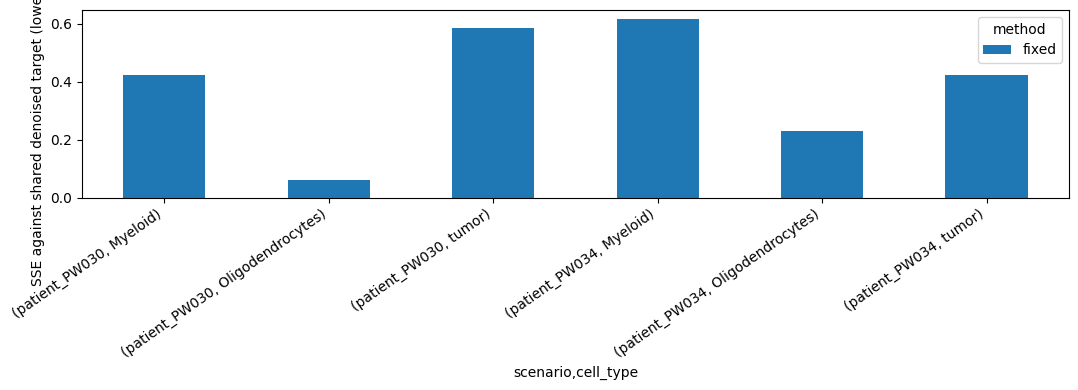

In [8]:
baseline_results = (pd.read_csv(OUT / 'baseline_metrics.csv')
                    if (OUT / 'baseline_metrics.csv').exists() else evaluate_methods())
baseline_results = denoised_results(baseline_results)
baseline_results.to_csv(OUT / 'baseline_metrics.csv', index=False)
show_results(baseline_results)


## Shift-network training

In this part, we freeze scDisInFact and train a small network to predict a shift for each cell:

$$
z'_u = z_u + \Delta_\phi(z_s, z_u, c_{\mathrm{src}}, c_{\mathrm{tgt}}).
$$

The network has two 64-unit hidden layers with ReLU. It takes the shared and treatment-specific latent means, plus one-hot source and target labels. It predicts the full shift instead of using the original difference of condition means.

We train it with MMD, comparing predicted expression with denoised target training cells from the same patient and cell type. Both are normalized to sum to 100 per cell and transformed with `log1p`. Cell-type labels group the comparisons but are not network inputs.

We use Adam with learning rate `1e-3` and up to 128 cells per group. The RBF kernel uses five bandwidth scales: 0.25, 0.5, 1, 2, and 4, with a base bandwidth estimated from up to 512 training cells. We select the checkpoint with the lowest validation MMD and stop after 10 epochs without improvement.

Gradients pass through the decoder to train our network, while the original model’s weights stay fixed.


Training adapter: network
network epoch 1 train 0.036477 val 0.018727
network epoch 2 train 0.013951 val 0.0079814
network epoch 3 train 0.0037959 val 0.0056576
network epoch 4 train 0.0036881 val 0.0059218
network epoch 5 train 0.0025805 val 0.0058617
network epoch 6 train 0.0028603 val 0.0062261
network epoch 7 train 0.003364 val 0.0056546
network epoch 8 train 0.0031933 val 0.0051906
network epoch 9 train 0.0032921 val 0.0061154
network epoch 10 train 0.0030537 val 0.0066052
network epoch 11 train 0.0032413 val 0.0056148
network epoch 12 train 0.0026498 val 0.0066331
network epoch 13 train 0.0025942 val 0.0068044
network epoch 14 train 0.0033548 val 0.0059002
network epoch 15 train 0.003202 val 0.0059797
network epoch 16 train 0.0030216 val 0.0058159
network epoch 17 train 0.0038948 val 0.0071114
network epoch 18 train 0.0025396 val 0.0054756


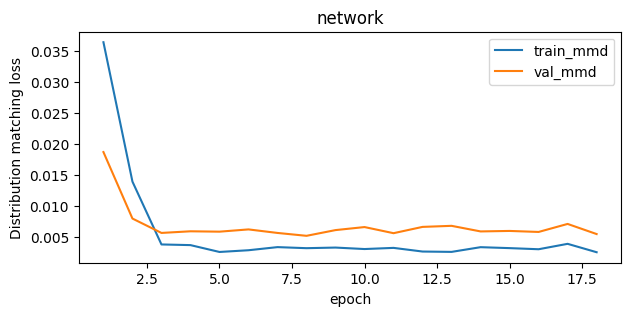

In [9]:
adapters = {}
for mode in ['network']:
    if (OUT / f'{mode}.pt').exists():
        from cellshift.model import Shift
        checkpoint = torch.load(OUT / f'{mode}.pt', map_location=backbone.device, weights_only=False)
        adapter = Shift(checkpoint['dims'], checkpoint['categories'], mode=mode).to(backbone.device)
        adapter.load_state_dict(checkpoint['state_dict'])
        adapter.eval()
        frame = pd.read_csv(OUT / f'{mode}_history.csv') if (OUT / f'{mode}_history.csv').exists() else None
        print('Network checkpoint loaded.')
    else:
        print('Training adapter:', mode, flush=True)
        adapter, history = train_adapter(backbone, train_encoded, val_encoded,
            training.meta, validation.meta, dims, mode, bandwidth, SEED,
            epochs=ADAPTER_EPOCHS, steps=STEPS)
        torch.save({'state_dict': adapter.state_dict(), 'mode': mode, 'dims': dims,
                    'categories': [len(x) for x in backbone.labels], 'bandwidth': bandwidth,
                    'centroids': [x.cpu() for x in backbone.centroids]}, OUT / f'{mode}.pt')
        frame = pd.DataFrame(history)
        frame.to_csv(OUT / f'{mode}_history.csv', index=False)
    adapters[mode] = adapter
    if frame is not None:
        frame.plot(x='epoch', y=['train_mmd', 'val_mmd'], title=mode, figsize=(7, 3))
        plt.ylabel('Distribution matching loss'); plt.show()


## Method comparison

In this part, we compare our network (`network`) with the original mean shift (`fixed`) on the same test cells. Both methods use the same denoised reference from the frozen scDisInFact model.

We report SSE, Pearson correlation, and R² for each cell type and prediction route. Lower SSE is better; higher Pearson and R² are better.

The second table shows the percentage reduction in SSE and the changes in Pearson and R². Positive values indicate improvement. Pearson and R² changes are calculated as network minus fixed.

The plots show all three metrics. These results are from one seed and compare mean expression within each cell type, not paired individual cells.


,scenario,cell_type,method,paper_sse,pearson,r2
0,patient_PW030,Myeloid,fixed,0.423591,0.989795,0.978471
1,patient_PW030,Myeloid,network,0.382145,0.990316,0.980577
2,patient_PW030,Oligodendrocytes,fixed,0.059382,0.996648,0.992891
3,patient_PW030,Oligodendrocytes,network,0.053476,0.996893,0.993598
4,patient_PW030,tumor,fixed,0.584523,0.982382,0.915671
5,patient_PW030,tumor,network,0.500640,0.983516,0.927772
6,patient_PW034,Myeloid,fixed,0.615898,0.990937,0.968697
7,patient_PW034,Myeloid,network,0.236499,0.994425,0.987980
8,patient_PW034,Oligodendrocytes,fixed,0.228535,0.996590,0.972641
9,patient_PW034,Oligodendrocytes,network,0.156363,0.997350,0.981281


method                             fixed   network  \
scenario      cell_type                              
patient_PW030 Myeloid           0.423591  0.382145   
              Oligodendrocytes  0.059382  0.053476   
              tumor             0.584523  0.500640   
patient_PW034 Myeloid           0.615898  0.236499   
              Oligodendrocytes  0.228535  0.156363   
              tumor             0.421067  0.427316   

method                          network_improvement_percent  pearson_change  \
scenario      cell_type                                                       
patient_PW030 Myeloid                              9.784327        0.000521   
              Oligodendrocytes                     9.944915        0.000246   
              tumor                               14.350656        0.001134   
patient_PW034 Myeloid                             61.600881        0.003488   
              Oligodendrocytes                    31.580024        0.000760   
              tumor                               -1.484170       -0.000397   

method                          r2_change  
scenario      cell_type                    
patient_PW030 Myeloid            0.002106  
              Oligodendrocytes   0.000707  
              tumor              0.012102  
patient_PW034 Myeloid            0.019283  
              Oligodendrocytes   0.008640  
              tumor             -0.000902

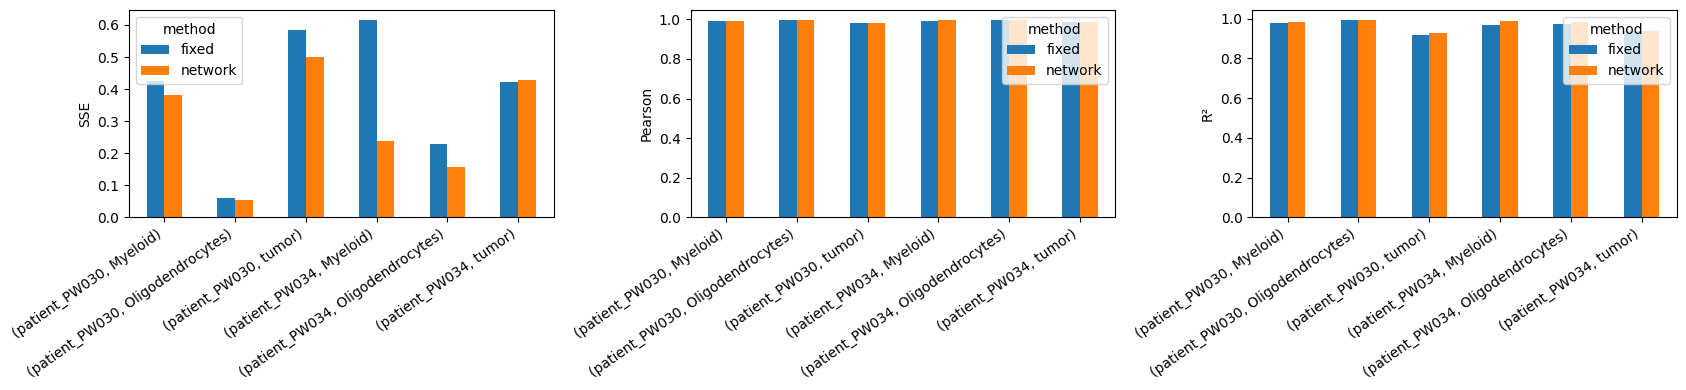

In [9]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'cellshift' / 'evaluation.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Repository root not found.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if 'OUT' not in globals():
    saved_results = sorted((ROOT / 'runs_notebook').glob('*/gbm/seed_0/metrics.csv'),
                           key=lambda path: path.stat().st_mtime)
    if not saved_results:
        raise FileNotFoundError('No saved GBM evaluation results were found.')
    OUT = saved_results[-1].parent

from importlib import reload
import cellshift.evaluation as evaluation
reload(evaluation)
from cellshift.evaluation import denoised_results, comparison_table, paired_improvements
results = (pd.read_csv(OUT / 'metrics.csv')
           if (OUT / 'metrics.csv').exists() else evaluate_methods(adapters))
results = denoised_results(results)
results.to_csv(OUT / 'metrics.csv', index=False)
display(comparison_table(results).round(6))
paired = paired_improvements(results)
display(paired.round(6))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric, label in zip(axes, ['paper_sse', 'pearson', 'r2'],
                            ['SSE', 'Pearson', 'R²']):
    values = results.pivot(index=['scenario', 'cell_type'], columns='method', values=metric)
    values[['fixed', 'network']].plot.bar(ax=ax)
    ax.set_ylabel(label)
    ax.set_xlabel('')
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.show()
